# BiciLogic - L3: several couriers (VRP)

One courier was a TSP. With **k couriers** we must *also* decide **who serves which stops** - that is the **Vehicle Routing Problem (VRP)**.

The objective matters:
- **min-sum**: minimize total distance. Tends to dump everything on one courier (a second courier means a second round-trip from the depot = extra km).
- **makespan**: minimize the *longest* single-courier route = workload balance. Slightly more total km, but fair and faster end-to-end.

We use **makespan**. The solver is **OR-Tools**, which optimizes assignment + ordering over the distance matrix we build from OSMnx (OR-Tools holds no map data; the geography still comes from the street graph).

In [1]:
import sys
sys.path.append("../src")

import osmnx as ox
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

from geo_utils import distance_matrix
from vrp import solve_vrp

ox.settings.use_cache = True

G = ox.graph_from_place("Ixelles, Brussels, Belgium", network_type="bike", simplify=True)
Gp = ox.project_graph(G)

## 1. A demand instance

We sample a depot + 24 delivery nodes from the **largest strongly connected component** (so every pair is reachable on the directed graph), then build the asymmetric distance matrix. Index 0 is the depot.

In [2]:
scc = max(nx.strongly_connected_components(Gp), key=len)
Gs = Gp.subgraph(scc).copy()
rng = np.random.default_rng(7)
stops = list(rng.choice(list(Gs.nodes), size=25, replace=False))   # index 0 = depot
D = distance_matrix(Gs, stops)
print("stops (incl. depot):", len(stops))

stops (incl. depot): 25


## 2. Solve with 3 couriers (makespan)

In [3]:
routes, lengths = solve_vrp(D, n_vehicles=3, objective="makespan", time_limit_s=5)
for v, (r, L) in enumerate(zip(routes, lengths)):
    print(f"courier {v+1}: {len(r)-2:2d} stops, {L:6d} m")
print(f"total = {sum(lengths)} m | makespan (max) = {max(lengths)} m")

courier 1:  8 stops,   6368 m
courier 2: 11 stops,   6629 m
courier 3:  5 stops,   6437 m
total = 19434 m | makespan (max) = 6629 m


Note the balance is by **distance**, not by number of stops: a courier with few but spread-out stops can carry as much distance as one with many clustered stops.

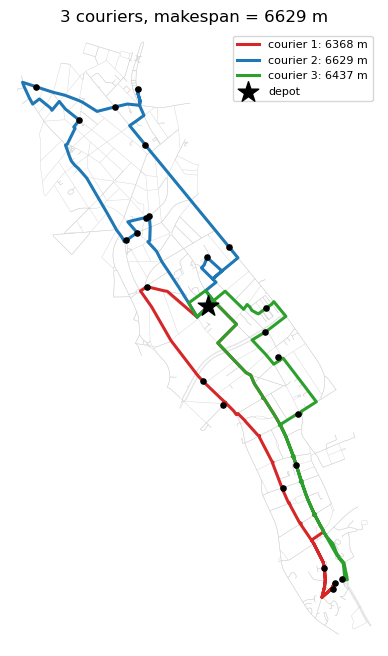

In [4]:
def full_path(G, node_seq):
    """Concatenate the real street paths between consecutive stops."""
    path = []
    for a, b in zip(node_seq[:-1], node_seq[1:]):
        p = nx.shortest_path(G, a, b, weight="length")
        path += p[1:] if path else p
    return path

fig, ax = ox.plot_graph(Gs, node_size=0, edge_linewidth=0.3, edge_color="lightgray",
                        bgcolor="white", show=False, close=False)
colors = ["tab:red", "tab:blue", "tab:green", "tab:purple", "tab:orange"]
for v, route in enumerate(routes):
    full = full_path(Gs, [stops[i] for i in route])
    xs = [Gs.nodes[n]["x"] for n in full]
    ys = [Gs.nodes[n]["y"] for n in full]
    ax.plot(xs, ys, color=colors[v], lw=2.2, zorder=4, label=f"courier {v+1}: {lengths[v]} m")
ax.scatter(Gs.nodes[stops[0]]["x"], Gs.nodes[stops[0]]["y"],
           c="black", s=240, marker="*", zorder=6, label="depot")
for i in range(1, len(stops)):
    ax.scatter(Gs.nodes[stops[i]]["x"], Gs.nodes[stops[i]]["y"], c="black", s=14, zorder=5)
ax.legend(loc="upper right", fontsize=8)
ax.set_title(f"3 couriers, makespan = {max(lengths)} m")
plt.show()

## 3. How many couriers? (fleet-size sweep)

Adding couriers cuts the makespan (each does less) but raises the **total** distance (more depot round-trips), with **diminishing returns**. The economic decision is: pick the *smallest* fleet whose makespan fits within a shift's time budget (plus a safety buffer for the unforeseen). Each extra courier is salary.

k=1: makespan= 13912 m | total= 13912 m


k=2: makespan=  8554 m | total= 17056 m


k=3: makespan=  6629 m | total= 19434 m


k=4: makespan=  6073 m | total= 21843 m


k=5: makespan=  6073 m | total= 21843 m


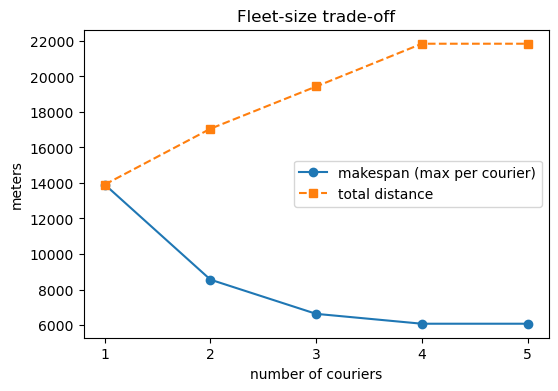

In [5]:
ks, makespans, totals = [], [], []
for k in [1, 2, 3, 4, 5]:
    _, L = solve_vrp(D, n_vehicles=k, objective="makespan", time_limit_s=4)
    ks.append(k); makespans.append(max(L)); totals.append(sum(L))
    print(f"k={k}: makespan={max(L):6d} m | total={sum(L):6d} m")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ks, makespans, "o-", label="makespan (max per courier)")
ax.plot(ks, totals, "s--", label="total distance")
ax.set_xlabel("number of couriers"); ax.set_ylabel("meters")
ax.set_xticks(ks); ax.legend(); ax.set_title("Fleet-size trade-off")
plt.show()

## What L3 delivered, and the bridge to L4

- A multi-courier VRP with a **workload-balancing** (makespan) objective, plus a **fleet-sizing** view (the economic trade-off between makespan and salary cost).
- Notice the balanced routes are already **roughly geographic territories**.

**But these territories are recomputed every day** - with different orders, a courier would get a different area each morning. **L4 (districting)** fixes that: pre-partition the city into *stable*, balanced zones that survive day-to-day demand variation.